In [ ]:
from google.colab import drive
from google.colab import files
drive.mount('/content/drive',force_remount=True)

Mounted at /content/drive


In [ ]:
train_dir =r'/content/drive/MyDrive/new_road_Dataset/train'
test_dir=r'/content/drive/MyDrive/new_road_Dataset/test'


In [ ]:

import tensorflow as tf
from tensorflow.keras import initializers
import os
import numpy as np
from tqdm import tqdm
from skimage.io import imread, imshow
from skimage.transform import resize
import matplotlib.pyplot as plt
import random
seed=14
np.random.seed=seed
img_width=512
img_height=512
img_channels=3

In [ ]:
train_dir =r'/content/drive/MyDrive/new_road_Dataset/train'
test_dir=r'/content/drive/MyDrive/new_road_Dataset/test'


In [ ]:
train_img_dir = os.path.join(train_dir,'images/')
train_mask_dir = os.path.join(train_dir,'masks/')
test_img_dir = os.path.join(test_dir,'images/')
test_mask_dir = os.path.join(test_dir,'masks/')

In [ ]:
print(train_img_dir)
test_img_count = len(os.listdir(test_img_dir))
train_img_count=len(os.listdir(train_img_dir))
train_img_ids = os.listdir(train_img_dir)
test_img_ids = os.listdir(test_img_dir)
train_mask_count=len(os.listdir(train_mask_dir))
train_mask_ids=os.listdir(train_mask_dir)
print('Train image count is',train_img_count,'and their ids are',train_img_ids)
print('Mask image count is',train_mask_count,'and theur ids are',train_mask_ids)

/content/drive/MyDrive/new_road_Dataset/train/images/
Train image count is 198 and their ids are ['img-131.png', 'img-120.png', 'img-123.png', 'img-143.png', 'img-133.png', 'img-126.png', 'img-128.png', 'img-150.png', 'img-119.png', 'img-147.png', 'img-142.png', 'img-149.png', 'img-148.png', 'img-113.png', 'img-107.png', 'img-144.png', 'img-111.png', 'img-114.png', 'img-135.png', 'img-104.png', 'img-116.png', 'img-125.png', 'img-141.png', 'img-146.png', 'img-132.png', 'img-140.png', 'img-137.png', 'img-13.png', 'img-136.png', 'img-1.png', 'img-127.png', 'img-118.png', 'img-138.png', 'img-152.png', 'img-100.png', 'img-108.png', 'img-14.png', 'img-151.png', 'img-130.png', 'img-112.png', 'img-106.png', 'img-102.png', 'img-139.png', 'img-145.png', 'img-103.png', 'img-109.png', 'img-134.png', 'img-15.png', 'img-117.png', 'img-105.png', 'img-10.png', 'img-110.png', 'img-12.png', 'img-121.png', 'img-129.png', 'img-11.png', 'img-101.png', 'img-124.png', 'img-153.png', 'img-115.png', 'img-122.p

In [ ]:
test_img_count=len(os.listdir(test_img_dir))
test_img_ids=os.listdir(test_img_dir)

In [ ]:
test_img_count = len(os.listdir(test_img_dir))
test_img_ids = os.listdir(test_img_dir)
print('Test image count is',test_img_count,'and their ids are',test_img_ids)

Test image count is 6 and their ids are ['img-2.png', 'img-4.png', 'img-3.png', 'img-1.png', 'img-6.png', 'img-5.png']


In [ ]:
X_train = np.zeros((train_mask_count,img_width,img_height,img_channels),dtype=np.uint8)
y_train = np.zeros((len(train_mask_ids),img_width,img_height,1),dtype=np.bool_)

In [ ]:
print('Resizing train images and masks')
for n,img_name in tqdm(enumerate(train_mask_ids),total=len(train_mask_ids)):
    path = train_img_dir + img_name
    img = imread(path)[:,:,:img_channels]
    img = resize(img,(img_width,img_height),mode='constant',preserve_range=True)
    X_train[n] = img
    mask = np.zeros((img_width,img_width,1),dtype=np.bool_)
    msk = imread(train_mask_dir+img_name)
    msk = np.expand_dims(resize(msk,(img_width,img_height),mode='constant',preserve_range=True),axis=-1)
    mask = np.maximum(mask,msk)
    y_train[n] = mask

Resizing train images and masks


100%|██████████| 198/198 [02:24<00:00,  1.37it/s]


In [ ]:
X_test = np.zeros((test_img_count,img_width,img_height,img_channels),dtype=np.uint8)
y_test_ground_truth = np.zeros((len(test_img_ids),img_width,img_height,1),dtype=np.bool_)


In [ ]:
print('Resizing test images')
for i,img_name in tqdm(enumerate(test_img_ids),total=len(test_img_ids)):
    path = test_img_dir + img_name
    img = imread(path)[:,:,:img_channels]
    img = resize(img,(img_width,img_height),mode='constant',preserve_range=True)
    X_test[i] = img

Resizing test images


100%|██████████| 6/6 [00:04<00:00,  1.44it/s]


In [ ]:
print('Resizing test masks')
for n,img_name in tqdm(enumerate(test_img_ids),total=len(test_img_ids)):
    mask = np.zeros((img_width,img_width,1),dtype=np.bool_)
    msk = imread(test_mask_dir+img_name)
    msk = np.expand_dims(resize(msk,(img_width,img_height),mode='constant',preserve_range=True),axis=-1)
    mask = np.maximum(mask,msk)
    y_test_ground_truth[n] = mask

Resizing test masks


100%|██████████| 6/6 [00:04<00:00,  1.43it/s]


In [ ]:
input_shape = (img_height, img_width, img_channels)

In [ ]:
from tensorflow.keras import models, layers, regularizers
from tensorflow.keras import backend as K
from tensorflow.keras.optimizers import Adam
#from evaluation_metrics import IoU_coef,IoU_loss

In [ ]:
import tensorflow as tf
from tensorflow.keras.layers import *
from tensorflow.keras.models import Model

In [ ]:
def aspp_block(x, num_filters, rate_scale=1):
    x1 = conv_block(num_filters, (3, 3), dilation_rate=(6 * rate_scale, 6 * rate_scale), padding="SAME")(x)
    x1 = layers.BatchNormalization()(x1)

    x2 = conv_block(num_filters, (3, 3), dilation_rate=(12 * rate_scale, 12 * rate_scale), padding="SAME")(x)
    x2 = layers.BatchNormalization()(x2)

    x3 = conv_block(num_filters, (3, 3), dilation_rate=(18 * rate_scale, 18 * rate_scale), padding="SAME")(x)
    x3 = layers.BatchNormalization()(x3)

    x4 = conv_block(num_filters, (3, 3), padding="SAME")(x)
    x4 = layers.BatchNormalization()(x4)

    y = Add()([x1, x2, x3, x4])
    y = conv_block(num_filters, (1, 1), padding="SAME")(y)
    return y


In [ ]:
def stem_block(x, n_filter, strides):
    x_init = x

    ## Conv 1
    x = Conv2D(n_filter, (3, 3), padding="same", strides=strides)(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = Conv2D(n_filter, (3, 3), padding="same")(x)

    ## Shortcut
    s  = Conv2D(n_filter, (1, 1), padding="same", strides=strides)(x_init)
    s = BatchNormalization()(s)

    ## Add
    x = Add()([x, s])
    return x



In [ ]:
def resnet_block(x, n_filter, strides=1):
    x_init = x

    ## Conv 1
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = Conv2D(n_filter, (3, 3), padding="same", strides=strides)(x)
    ## Conv 2
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = Conv2D(n_filter, (3, 3), padding="same", strides=1)(x)

    ## Shortcut
    s  = Conv2D(n_filter, (1, 1), padding="same", strides=strides)(x_init)
    s = BatchNormalization()(s)

    ## Add
    x = Add()([x, s])
    
    return x

In [ ]:
def aspp_block(x, num_filters, rate_scale=1):
    x1 = Conv2D(num_filters, (3, 3), dilation_rate=(6 * rate_scale, 6 * rate_scale), padding="SAME")(x)
    x1 = BatchNormalization()(x1)

    x2 = Conv2D(num_filters, (3, 3), dilation_rate=(12 * rate_scale, 12 * rate_scale), padding="SAME")(x)
    x2 = BatchNormalization()(x2)

    x3 = Conv2D(num_filters, (3, 3), dilation_rate=(18 * rate_scale, 18 * rate_scale), padding="SAME")(x)
    x3 = BatchNormalization()(x3)

    x4 = Conv2D(num_filters, (3, 3), padding="SAME")(x)
    x4 = BatchNormalization()(x4)

    y = Add()([x1, x2, x3, x4])
    y = Conv2D(num_filters, (1, 1), padding="SAME")(y)
    return y

In [ ]:
def attetion_block(g, x):
    """
        g: Output of Parallel Encoder block
        x: Output of Previous Decoder block
    """

    filters = x.shape[-1]

    g_conv = BatchNormalization()(g)
    g_conv = Activation("relu")(g_conv)
    g_conv = Conv2D(filters, (3, 3), padding="SAME")(g_conv)

    g_pool = MaxPooling2D(pool_size=(2, 2), strides=(2, 2))(g_conv)

    x_conv = BatchNormalization()(x)
    x_conv = Activation("relu")(x_conv)
    x_conv = Conv2D(filters, (3, 3), padding="SAME")(x_conv)

    gc_sum = Add()([g_pool, x_conv])

    gc_conv = BatchNormalization()(gc_sum)
    gc_conv = Activation("relu")(gc_conv)
    gc_conv = Conv2D(filters, (3, 3), padding="SAME")(gc_conv)

    gc_mul = Multiply()([gc_conv, x])
    return gc_mul

In [ ]:
#Attention U-NET
def attentionunet(input_shape, dropout=0.2, batchnorm=True):

    n_filters = [16, 32, 64, 128, 256]
    kernelsize = 3
    upsample_size = 2

    inputs = layers.Input(input_shape)
    c0 = inputs
    c1 = stem_block(c0, n_filters[0], strides=1)

    ## Encoder
    c2 = resnet_block(c1, n_filters[1], strides=2)
    c3 = resnet_block(c2, n_filters[2], strides=2)
    c4 = resnet_block(c3, n_filters[3], strides=2)
    c5 = resnet_block(c4, n_filters[4], strides=2)

    ## Bridge
    b1 = aspp_block(c5, n_filters[4])
    #b2 = aspp_block(c4, n_filters[3])

    ## Decoder
    d0 = attetion_block(c4, b1)
    d0 = UpSampling2D((2, 2))(d0)
    d0 = Concatenate()([d0, c4])
    d0 = resnet_block(d0, n_filters[4])

    #d1 = attetion_block(c3, b2)
    d1 = attetion_block(c3, d0)
    d1 = UpSampling2D((2, 2))(d1)
    d1 = Concatenate()([d1, c3])
    d1 = resnet_block(d1, n_filters[3])


    d2 = attetion_block(c2, d1)
    d2 = UpSampling2D((2, 2))(d2)
    d2 = Concatenate()([d2, c2])
    d2 = resnet_block(d2, n_filters[2])

    d3 = attetion_block(c1, d2)
    d3 = UpSampling2D((2, 2))(d3)
    d3 = Concatenate()([d3, c1])
    d3 = resnet_block(d3, n_filters[1])

    ## output
    #outputs = aspp_block(d3, n_filters[0])
    outputs=d3
    outputs = Conv2D(1, (1, 1), padding="same")(outputs)
    outputs = Activation("sigmoid")(outputs)

    ## Model
    model = Model(inputs, outputs)
    model.summary()
    return model


In [ ]:
model = attentionunet(input_shape)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 512, 512,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 512, 512,  │        448 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 512, 512,  │         64 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 512, 512,  │          0 │ batch_normalizat… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 512, 512,  │         64 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 512, 512,  │      2,320 │ activation[0][0]  │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 512, 512,  │         64 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 512, 512,  │          0 │ conv2d_1[0][0],   │
│                     │ 16)               │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 16)        │          0 │ add[0][0]         │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 1, 16)  │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 1, 1, 2)   │         32 │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1, 1, 16)  │         32 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 512, 512,  │          0 │ add[0][0],        │
│                     │ 16)               │            │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 512, 512,  │         64 │ multiply[0][0]    │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 512, 512,  │          0 │ batch_normalizat… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 256, 256,  │      4,640 │ activation_1[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        128 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 256, 256,  │          0 │ batch_normalizat

 Total params: 9,196,209 (35.08 MB)

 Trainable params: 9,184,593 (35.04 MB)

 Non-trainable params: 11,616 (45.38 KB)

In [ ]:

# Compile the model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Early Stopping
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    min_delta=0.0001,
    mode='min',
    restore_best_weights=True,
    verbose=1
)

# Model Checkpoint
model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath='best_attention_unet.keras',
    monitor='val_loss',
    save_best_only=True,
    mode='min',
    verbose=1
)

# TensorBoard
tensorboard = tf.keras.callbacks.TensorBoard(
    log_dir='logs'
)

# Callback configuration
callbacks = [
    early_stopping,
    model_checkpoint,
    tensorboard
]

# Train the model
results = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    batch_size=16,
    epochs=100,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10s/step - accuracy: 0.6990 - loss: 0.5754  
Epoch 1: val_loss improved from None to inf, saving model to best_attention_unet.keras

Epoch 1: finished saving model to best_attention_unet.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 231s 12s/step - accuracy: 0.7709 - loss: 0.4806 - val_accuracy: 0.8281 - val_loss: inf
Epoch 2/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 245ms/step - accuracy: 0.8394 - loss: 0.3582
Epoch 2: val_loss improved from inf to 71120988277701444081025024.00000, saving model to best_attention_unet.keras

Epoch 2: finished saving model to best_attention_unet.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 382ms/step - accuracy: 0.8391 - loss: 0.3591 - val_accuracy: 0.8351 - val_loss: 71120988277701444081025024.0000
Epoch 3/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 244ms/step - accuracy: 0.8425 - loss: 0.3476
Epoch 3: val_loss improved from 71120988277701444081025024.00000 to 75554278508767215616.00000, saving model to best_attention_unet.keras

Epoch 3: finished sa

{'accuracy': [0.7708539366722107, 0.8391370177268982, 0.8444015979766846, 0.8492429852485657, 0.8528909087181091, 0.8569080829620361, 0.8612346649169922, 0.8645827174186707, 0.8674905300140381, 0.8700252771377563, 0.8754557371139526, 0.8865715861320496, 0.8911918997764587, 0.8917840123176575, 0.89165198802948, 0.8924868702888489, 0.9005231261253357, 0.9048577547073364, 0.9119187593460083, 0.911703884601593, 0.9131117463111877, 0.9186077117919922, 0.9180000424385071, 0.920786440372467, 0.92399662733078, 0.9266253113746643, 0.9341263771057129, 0.9347226023674011, 0.9382063746452332, 0.9373695254325867, 0.9382084608078003, 0.9412980675697327, 0.9428038597106934, 0.9435811042785645, 0.9448485374450684, 0.9514272212982178, 0.9530465602874756, 0.9556546807289124, 0.9586625099182129, 0.9594734311103821, 0.9643271565437317, 0.9659740328788757, 0.9681071043014526, 0.9669500589370728, 0.9694545865058899, 0.9721620678901672, 0.9728643894195557, 0.9742285013198853, 0.9739823937416077, 0.9755359888

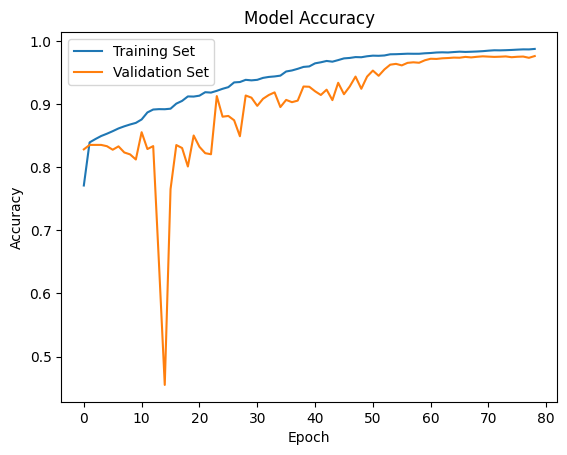

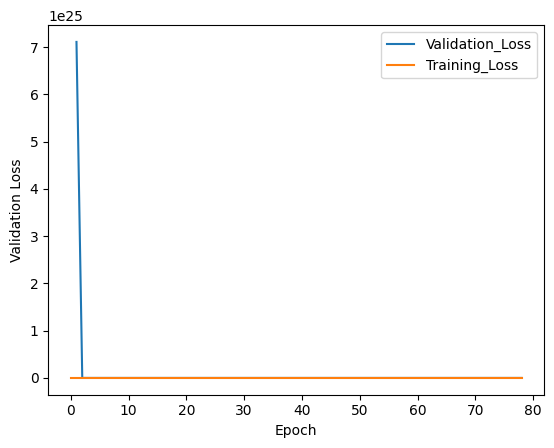

In [ ]:
print(results.history)
ax1 = plt.plot(results.history['accuracy'])
ax1 = plt.plot(results.history['val_accuracy'])
ax1 = plt.title('Model Accuracy')
ax1 = plt.ylabel('Accuracy')
ax1 = plt.xlabel('Epoch')
ax1 = plt.legend(['Training Set', 'Validation Set'])
plt.show()
ax2 = plt.plot(results.history['val_loss'])
ax2=plt.plot(results.history['loss'])
ax2 = plt.ylabel('Validation Loss')
ax2 = plt.xlabel('Epoch')
ax2 = plt.legend(['Validation_Loss', 'Training_Loss'])
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 12s 12s/step
Precision     : 0.9704
Recall        : 0.8194
F1 Score      : 0.8885
Dice Score    : 0.8885
Accuracy      : 0.9394
IoU Score     : 0.7994
Confusion Matrix:
[[1097868   11564]
 [  83698  379734]]


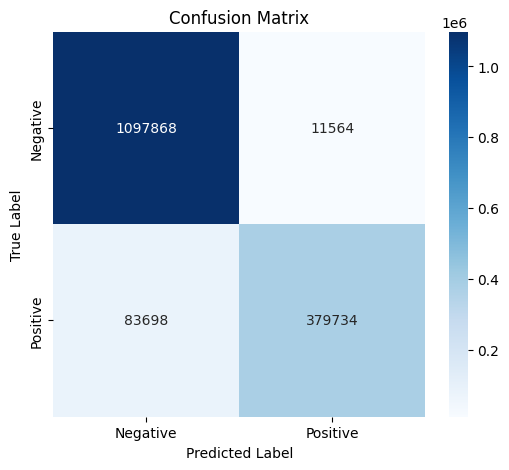

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, confusion_matrix
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, confusion_matrix

# Assuming the rest of the code is already executed:
y_pred = model.predict(X_test)
y_pred_binary = (y_pred > 0.5).astype(np.bool_)
y_true_flat = y_test_ground_truth.flatten()
y_pred_flat = y_pred_binary.flatten()

# Metrics
precision = precision_score(y_true_flat, y_pred_flat)
recall = recall_score(y_true_flat, y_pred_flat)
f1 = f1_score(y_true_flat, y_pred_flat)
accuracy = accuracy_score(y_true_flat, y_pred_flat)
conf_matrix = confusion_matrix(y_true_flat, y_pred_flat)
tn, fp, fn, tp = confusion_matrix(y_true_flat, y_pred_flat).ravel()
iou = tp / (tp + fp + fn)
# Print metrics
print(f"Precision     : {precision:.4f}")
print(f"Recall        : {recall:.4f}")
print(f"F1 Score      : {f1:.4f}")
print(f"Dice Score    : {f1:.4f}")
print(f"Accuracy      : {accuracy:.4f}")
print(f"IoU Score     : {iou:.4f}")
print("Confusion Matrix:")
print(conf_matrix)

# Plot confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()


In [ ]:
y_test_ground_truth = np.zeros((len(test_img_ids),img_width,img_height,1),dtype=np.bool_)

print('Resizing test masks')
for n,img_name in tqdm(enumerate(test_img_ids),total=len(test_img_ids)):
    mask = np.zeros((img_width,img_width,1),dtype=np.bool_)
    msk = imread(test_mask_dir+img_name)
    msk = np.expand_dims(resize(msk,(img_width,img_height),mode='constant',preserve_range=True),axis=-1)
    mask = np.maximum(mask,msk)
    y_test_ground_truth[n] = mask

Resizing test masks


100%|██████████| 6/6 [00:00<00:00, 73.82it/s]


6/6 ━━━━━━━━━━━━━━━━━━━━ 34s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 14s 14s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 136ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step


/tmp/ipykernel_536/3004066647.py:20: FutureWarning: `imshow` is deprecated since version 0.25 and will be removed in version 0.27. Please use `matplotlib`, `napari`, etc. to visualize images.
  imshow(X_test[i])


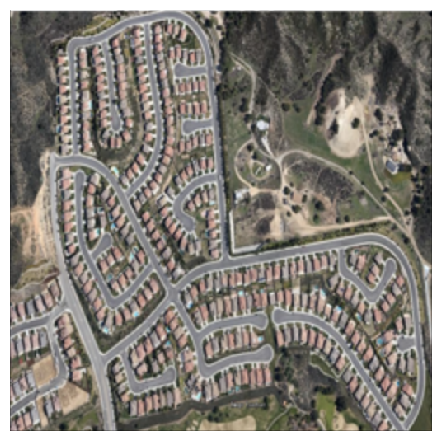

/tmp/ipykernel_536/3004066647.py:23: FutureWarning: `imshow` is deprecated since version 0.25 and will be removed in version 0.27. Please use `matplotlib`, `napari`, etc. to visualize images.
  imshow(pred_test[i])


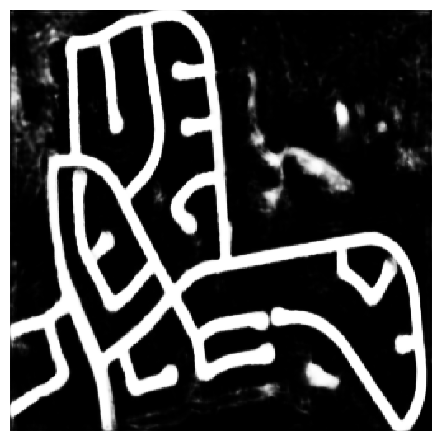

/tmp/ipykernel_536/3004066647.py:28: FutureWarning: `imshow` is deprecated since version 0.25 and will be removed in version 0.27. Please use `matplotlib`, `napari`, etc. to visualize images.
  imshow(pred_test_t[i])
/usr/local/lib/python3.13/dist-packages/skimage/io/_plugins/matplotlib_plugin.py:158: UserWarning: Low image data range; displaying image with stretched contrast.
  lo, hi, cmap = _get_display_range(image)


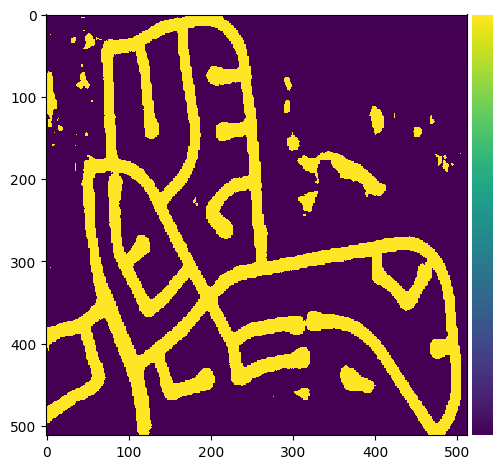

/tmp/ipykernel_536/3004066647.py:20: FutureWarning: `imshow` is deprecated since version 0.25 and will be removed in version 0.27. Please use `matplotlib`, `napari`, etc. to visualize images.
  imshow(X_test[i])


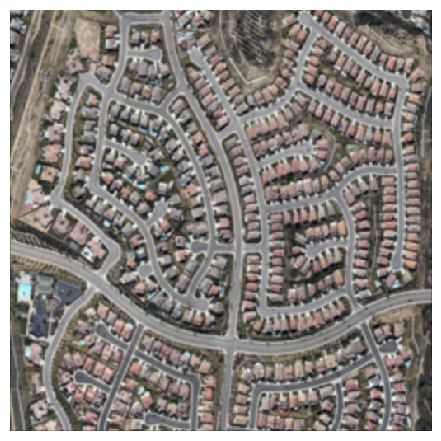

/tmp/ipykernel_536/3004066647.py:23: FutureWarning: `imshow` is deprecated since version 0.25 and will be removed in version 0.27. Please use `matplotlib`, `napari`, etc. to visualize images.
  imshow(pred_test[i])


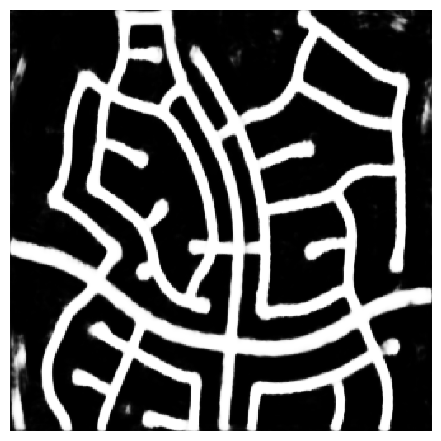

/tmp/ipykernel_536/3004066647.py:28: FutureWarning: `imshow` is deprecated since version 0.25 and will be removed in version 0.27. Please use `matplotlib`, `napari`, etc. to visualize images.
  imshow(pred_test_t[i])
/usr/local/lib/python3.13/dist-packages/skimage/io/_plugins/matplotlib_plugin.py:158: UserWarning: Low image data range; displaying image with stretched contrast.
  lo, hi, cmap = _get_display_range(image)


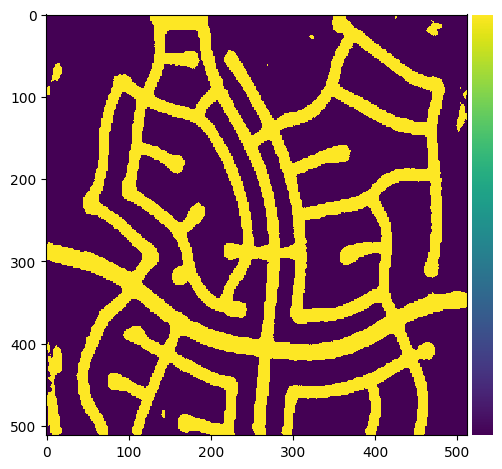

/tmp/ipykernel_536/3004066647.py:20: FutureWarning: `imshow` is deprecated since version 0.25 and will be removed in version 0.27. Please use `matplotlib`, `napari`, etc. to visualize images.
  imshow(X_test[i])


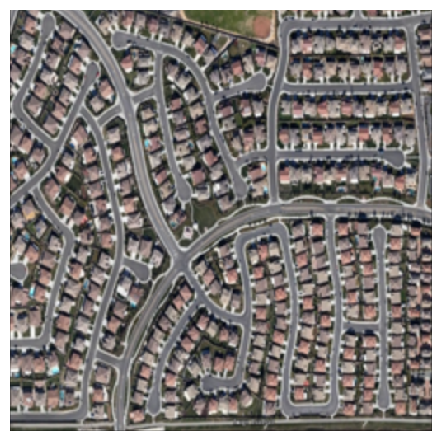

/tmp/ipykernel_536/3004066647.py:23: FutureWarning: `imshow` is deprecated since version 0.25 and will be removed in version 0.27. Please use `matplotlib`, `napari`, etc. to visualize images.
  imshow(pred_test[i])


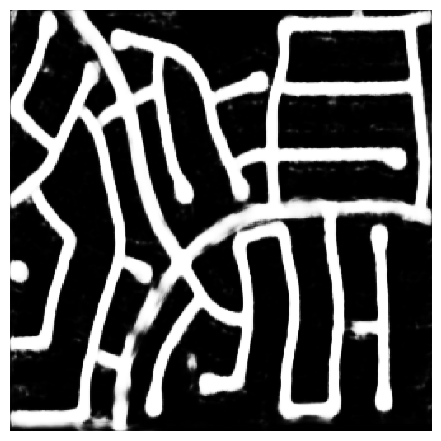

/tmp/ipykernel_536/3004066647.py:28: FutureWarning: `imshow` is deprecated since version 0.25 and will be removed in version 0.27. Please use `matplotlib`, `napari`, etc. to visualize images.
  imshow(pred_test_t[i])
/usr/local/lib/python3.13/dist-packages/skimage/io/_plugins/matplotlib_plugin.py:158: UserWarning: Low image data range; displaying image with stretched contrast.
  lo, hi, cmap = _get_display_range(image)


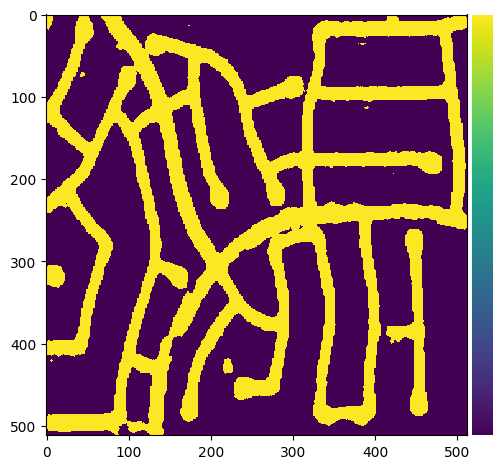

/tmp/ipykernel_536/3004066647.py:20: FutureWarning: `imshow` is deprecated since version 0.25 and will be removed in version 0.27. Please use `matplotlib`, `napari`, etc. to visualize images.
  imshow(X_test[i])


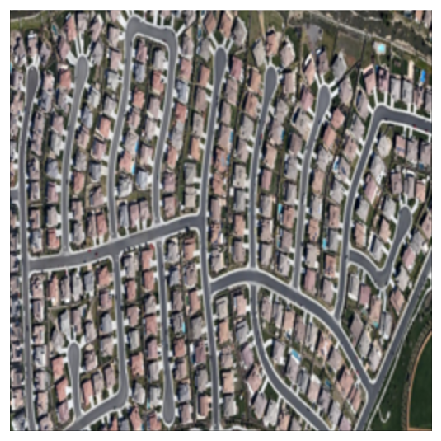

/tmp/ipykernel_536/3004066647.py:23: FutureWarning: `imshow` is deprecated since version 0.25 and will be removed in version 0.27. Please use `matplotlib`, `napari`, etc. to visualize images.
  imshow(pred_test[i])


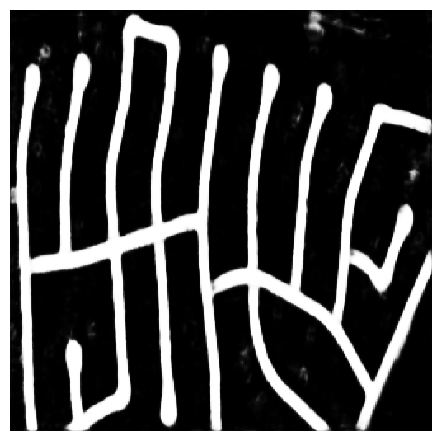

/tmp/ipykernel_536/3004066647.py:28: FutureWarning: `imshow` is deprecated since version 0.25 and will be removed in version 0.27. Please use `matplotlib`, `napari`, etc. to visualize images.
  imshow(pred_test_t[i])
/usr/local/lib/python3.13/dist-packages/skimage/io/_plugins/matplotlib_plugin.py:158: UserWarning: Low image data range; displaying image with stretched contrast.
  lo, hi, cmap = _get_display_range(image)


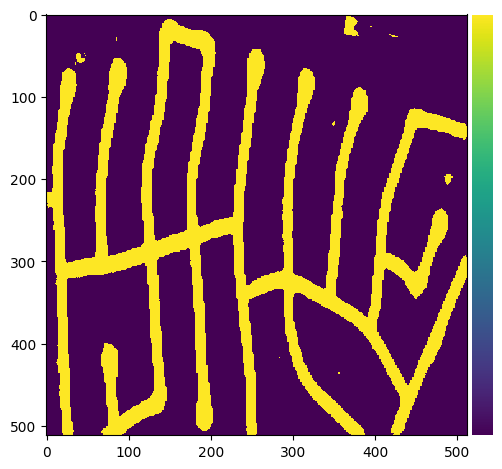

/tmp/ipykernel_536/3004066647.py:20: FutureWarning: `imshow` is deprecated since version 0.25 and will be removed in version 0.27. Please use `matplotlib`, `napari`, etc. to visualize images.
  imshow(X_test[i])


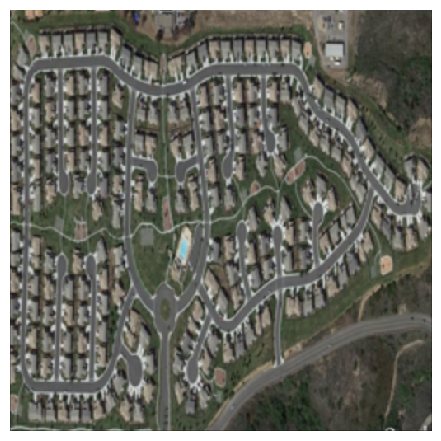

/tmp/ipykernel_536/3004066647.py:23: FutureWarning: `imshow` is deprecated since version 0.25 and will be removed in version 0.27. Please use `matplotlib`, `napari`, etc. to visualize images.
  imshow(pred_test[i])


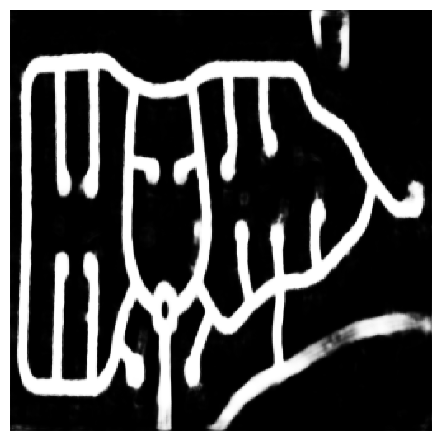

/tmp/ipykernel_536/3004066647.py:28: FutureWarning: `imshow` is deprecated since version 0.25 and will be removed in version 0.27. Please use `matplotlib`, `napari`, etc. to visualize images.
  imshow(pred_test_t[i])
/usr/local/lib/python3.13/dist-packages/skimage/io/_plugins/matplotlib_plugin.py:158: UserWarning: Low image data range; displaying image with stretched contrast.
  lo, hi, cmap = _get_display_range(image)


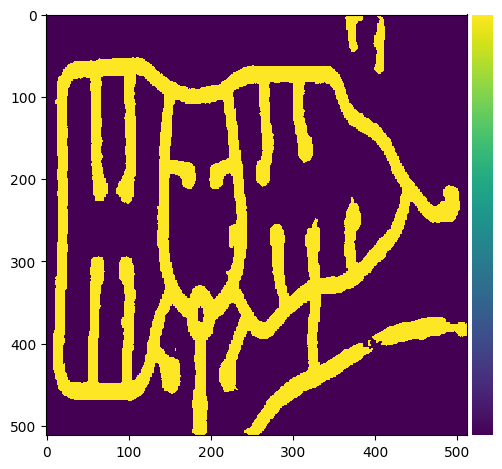

/tmp/ipykernel_536/3004066647.py:20: FutureWarning: `imshow` is deprecated since version 0.25 and will be removed in version 0.27. Please use `matplotlib`, `napari`, etc. to visualize images.
  imshow(X_test[i])


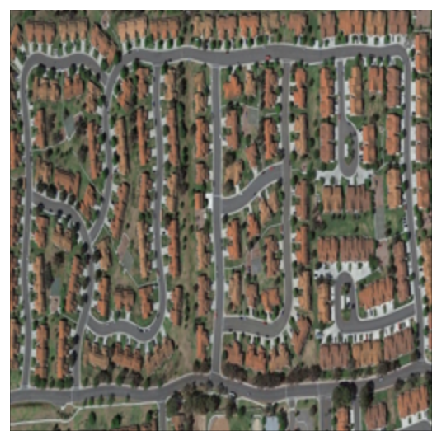

/tmp/ipykernel_536/3004066647.py:23: FutureWarning: `imshow` is deprecated since version 0.25 and will be removed in version 0.27. Please use `matplotlib`, `napari`, etc. to visualize images.
  imshow(pred_test[i])


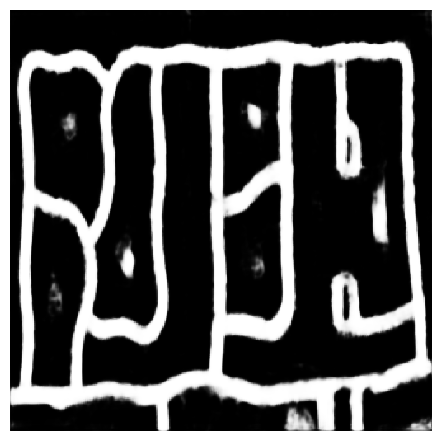

/tmp/ipykernel_536/3004066647.py:28: FutureWarning: `imshow` is deprecated since version 0.25 and will be removed in version 0.27. Please use `matplotlib`, `napari`, etc. to visualize images.
  imshow(pred_test_t[i])
/usr/local/lib/python3.13/dist-packages/skimage/io/_plugins/matplotlib_plugin.py:158: UserWarning: Low image data range; displaying image with stretched contrast.
  lo, hi, cmap = _get_display_range(image)


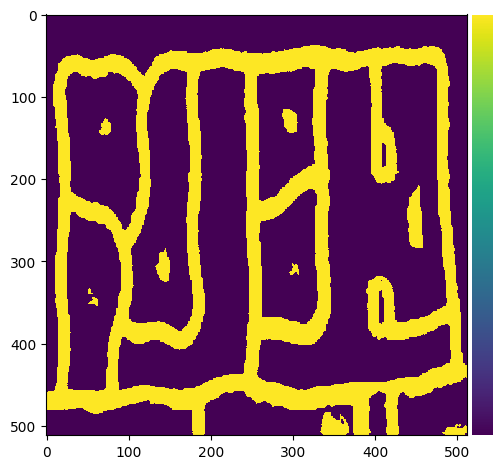

In [ ]:
idx = random.randint(1,len(X_train))

pred_train = model.predict(X_train[:int(X_train.shape[0]*0.9)],verbose=1)
pred_val = model.predict(X_train[int(X_train.shape[0]*0.9):],verbose=1)
pred_test = model.predict(X_test,verbose=1)

pred_train = model.predict(X_train[:int(X_train.shape[0]*0.9)],verbose=1)
pred_val = model.predict(X_train[int(X_train.shape[0]*0.9):],verbose=1)
pred_test = model.predict(X_test,verbose=1)

#Probability thresholds --------------------------------------------------------------------
pred_train_t = (pred_train>0.3).astype(np.uint8)
pred_val_t = (pred_val>0.3).astype(np.uint8)
pred_test_t = (pred_test>0.3).astype(np.uint8)

#checking performance on entire test set

for i in range(0,test_img_count):

    imshow(X_test[i])
    plt.axis('off')
    plt.show()
    imshow(pred_test[i])
    #imshow(np.squeeze(pred_test[i]))
    plt.axis('off')
    plt.show()
    #imshow(np.squeeze(pred_test_t[i]))
    imshow(pred_test_t[i])
    plt.axis('off')
    plt.show()


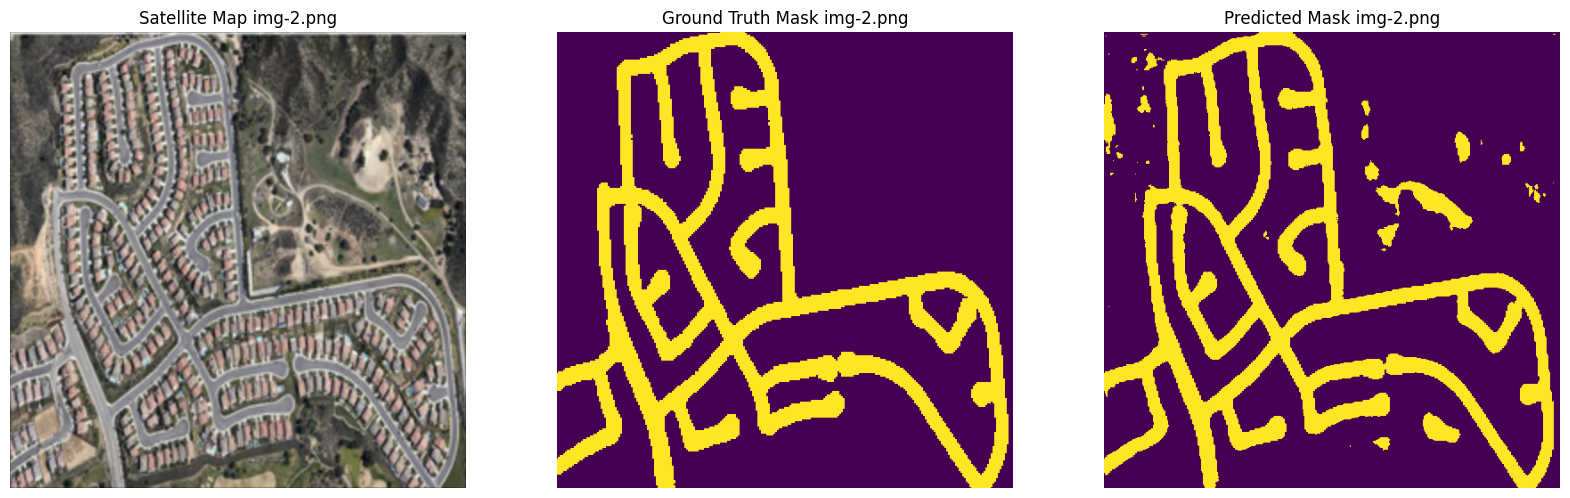

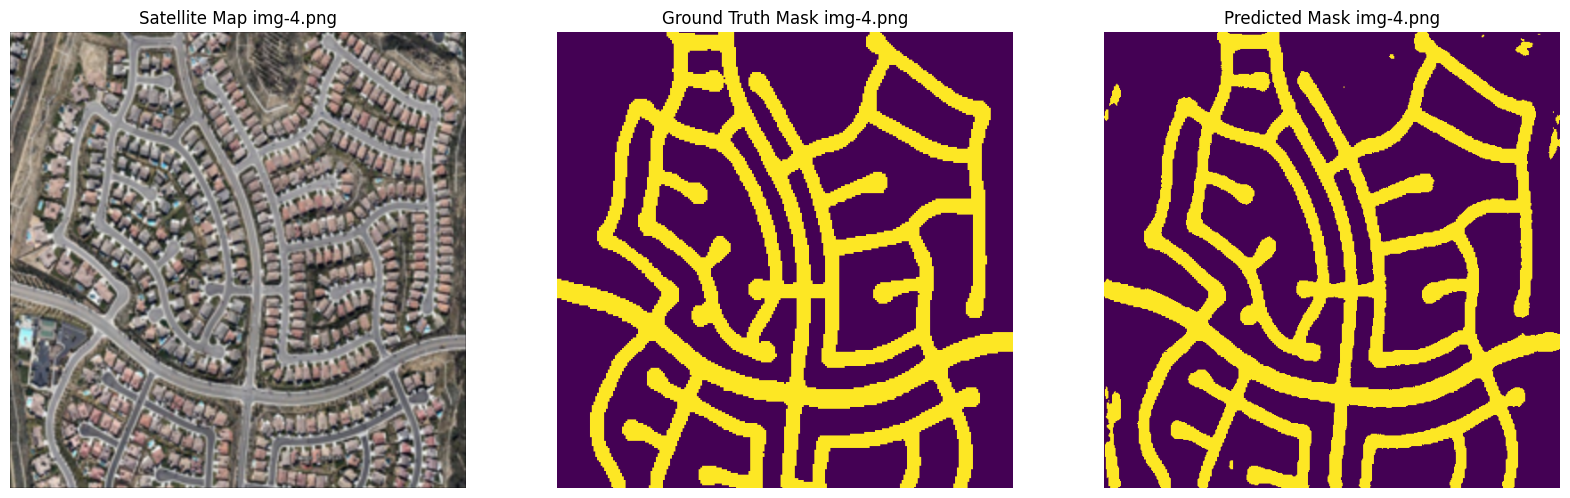

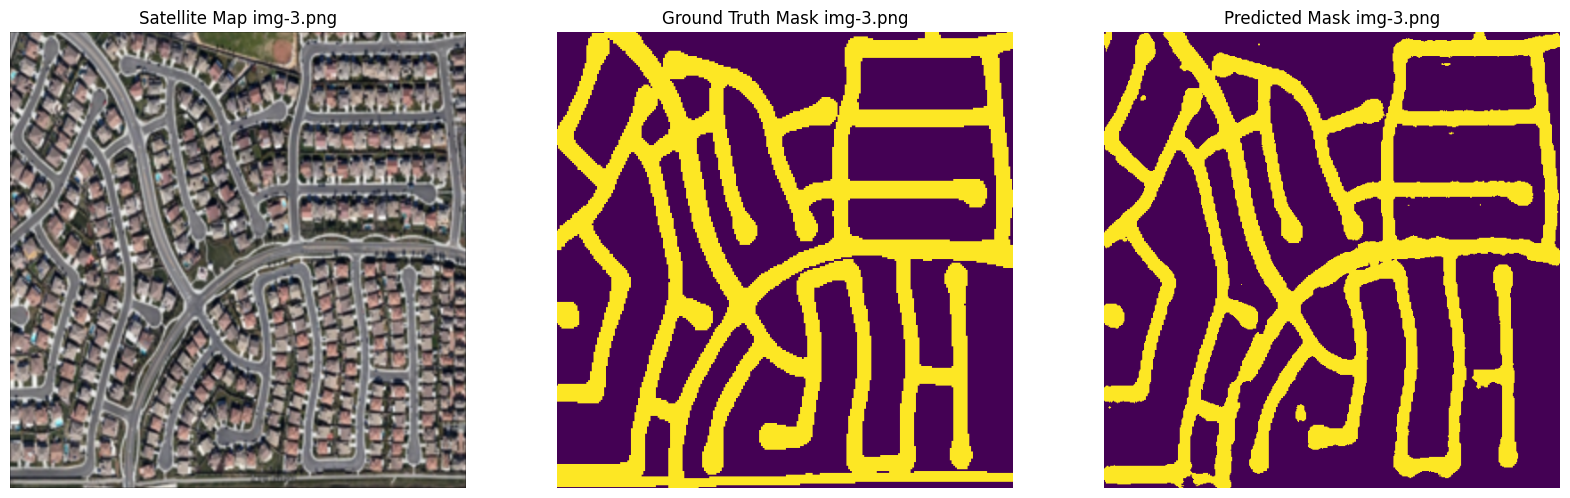

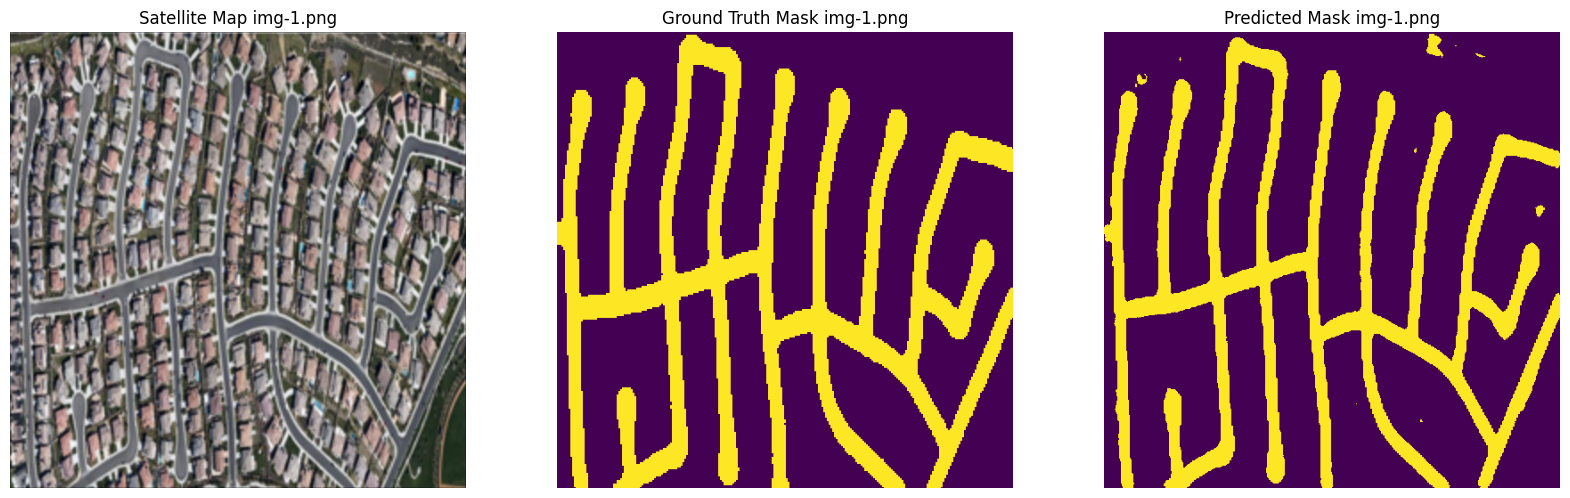

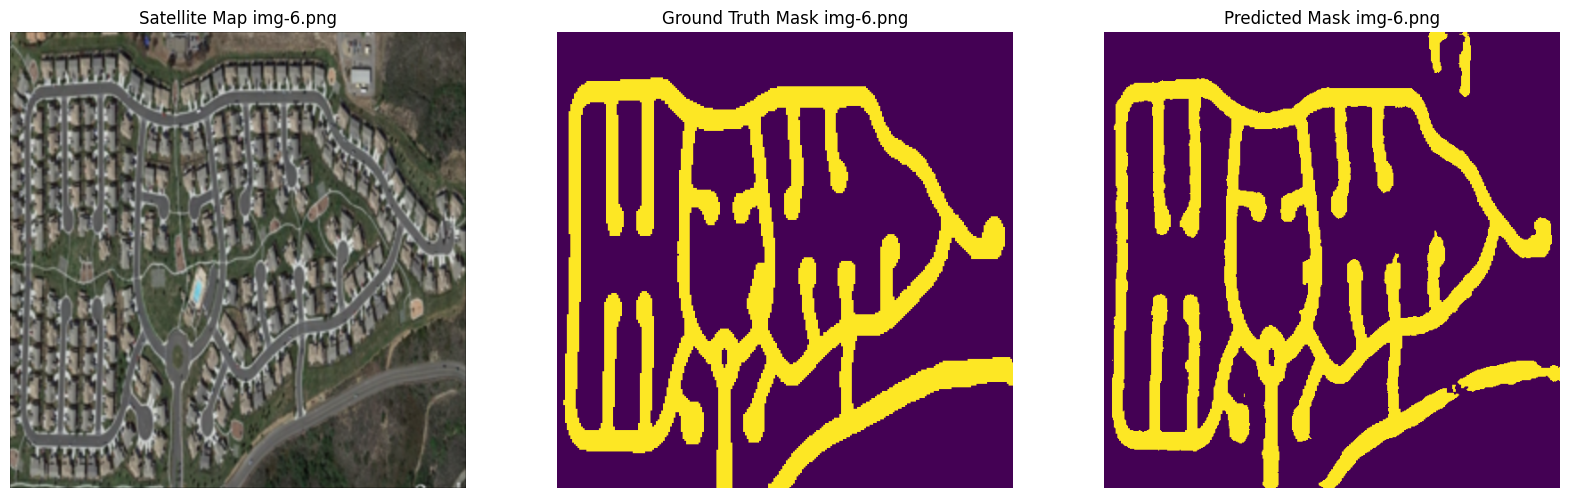

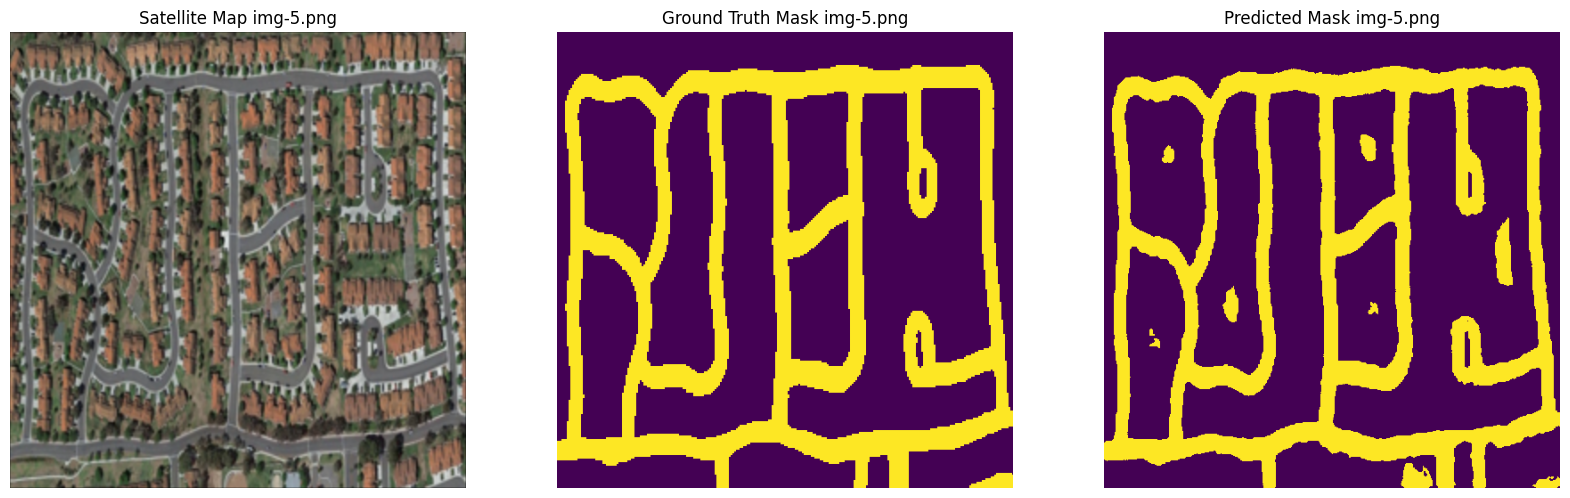

In [ ]:
#checking performance on entire test set

for i in range(0,len(test_img_ids)):
    fig, ((ax0, ax1, ax2)) = plt.subplots(1,3, figsize=(20,7))

    ax0.imshow(X_test[i])
    ax0.axis('off')
    ax0.set_title('Satellite Map %s'%(test_img_ids[i]))

    ax1.imshow(np.squeeze(y_test_ground_truth[i]+0))
    ax1.axis('off')
    ax1.set_title('Ground Truth Mask %s'%(test_img_ids[i]))

    # continuous mask
    ax2.imshow(np.squeeze(pred_test_t[i]))
    ax2.axis('off')
    ax2.set_title('Predicted Mask %s'%(test_img_ids[i]))


Tuning on validation images...
  thr=0.30 gap= 0 spur= 0 -> val APLS 0.7328
  thr=0.30 gap= 0 spur=10 -> val APLS 0.7312
  thr=0.30 gap=20 spur= 0 -> val APLS 0.7352
  thr=0.30 gap=20 spur=10 -> val APLS 0.7335
  thr=0.40 gap= 0 spur= 0 -> val APLS 0.7361
  thr=0.40 gap= 0 spur=10 -> val APLS 0.7281
  thr=0.40 gap=20 spur= 0 -> val APLS 0.7402
  thr=0.40 gap=20 spur=10 -> val APLS 0.7323
  thr=0.50 gap= 0 spur= 0 -> val APLS 0.7200
  thr=0.50 gap= 0 spur=10 -> val APLS 0.7161
  thr=0.50 gap=20 spur= 0 -> val APLS 0.7233
  thr=0.50 gap=20 spur=10 -> val APLS 0.7194
Best settings: {'thr': 0.4, 'max_gap': 20, 'spur': 0}  (val APLS 0.7402)

Image 001 - APLS: 0.7078
Image 002 - APLS: 0.7252
Image 003 - APLS: 0.6204
Image 004 - APLS: 0.7279
Image 005 - APLS: 0.8134
Image 006 - APLS: 0.6377

=========== APLS SUMMARY (TEST) ===========
Settings         : {'thr': 0.4, 'max_gap': 20, 'spur': 0}
Images evaluated : 6 / 6
Mean APLS        : 0.7054
Median APLS      : 0.7165
Std              : 0.0637

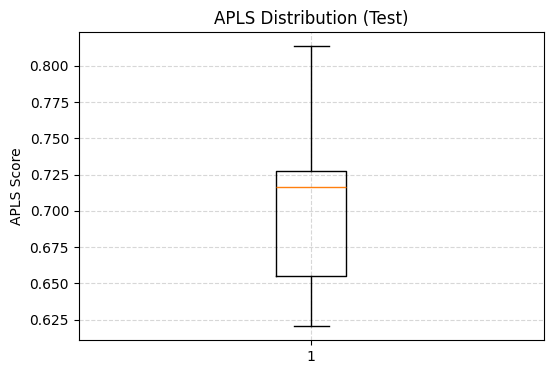

In [ ]:
# ============ APLS EVALUATION: improved, single cell ============
# Needs: model, X_test, y_test_ground_truth, X_train, y_train

import numpy as np, networkx as nx, random, itertools, matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from scipy.ndimage import convolve
from skimage.morphology import skeletonize, remove_small_objects, binary_closing, disk
from skimage.measure import label
from skimage.draw import line

# ---------------- Settings ----------------
USE_TTA   = True            # 8x flip/rotate averaging (slower, better)
TUNE      = True            # tune postprocessing on VALIDATION data (not test)
N_VAL     = 20              # validation images used for tuning
GRID_THR  = (0.3, 0.4, 0.5)
GRID_GAP  = (0, 20)         # max gap (px) to bridge
GRID_SPUR = (0, 10)         # spur length (px) to prune
DEFAULT   = dict(thr=0.4, max_gap=20, spur=10)   # used if TUNE=False
MIN_SIZE, CLOSE_R = 150, 2
BUFFER, N_NODES, SEED = 4, 60, 42

# ---------------- Prediction (optional TTA) ----------------
def predict_probs(X, bs=4):
    if not USE_TTA:
        return model.predict(X, batch_size=bs, verbose=0)
    out = np.zeros(X.shape[:3] + (1,), np.float32)
    for k in range(4):
        for flip in (False, True):
            x = np.rot90(X, k, axes=(1, 2))
            if flip: x = x[:, :, ::-1]
            p = model.predict(np.ascontiguousarray(x), batch_size=bs, verbose=0)
            if flip: p = p[:, :, ::-1]
            out += np.rot90(p, -k, axes=(1, 2))
    return out / 8.0

# ---------------- Mask -> skeleton -> graph ----------------
def bridge_gaps(skel, max_gap):
    if max_gap <= 0: return skel
    skel = skel.copy()
    pts = np.argwhere(skel)
    if len(pts) < 2: return skel
    lab = label(skel, connectivity=2)
    nb = convolve(skel.astype(np.uint8), np.ones((3, 3), np.uint8), mode="constant") - 1
    ends = np.argwhere(skel & (nb == 1))
    tree = cKDTree(pts)
    kq = min(100, len(pts))
    for y, x in ends:
        d, j = tree.query([y, x], k=kq, distance_upper_bound=max_gap)
        for dd, jj in zip(np.atleast_1d(d), np.atleast_1d(j)):
            if np.isinf(dd): break
            py, px = pts[jj]
            if lab[py, px] != lab[y, x]:           # different component -> connect
                rr, cc = line(y, x, py, px); skel[rr, cc] = True
                break
    return skeletonize(skel)

def pred_to_skeleton(prob, thr, max_gap):
    m = prob.squeeze() > thr
    if CLOSE_R > 0: m = binary_closing(m, disk(CLOSE_R))
    if MIN_SIZE > 0: m = remove_small_objects(m, MIN_SIZE)
    return bridge_gaps(skeletonize(m), max_gap)

def skel_to_graph(skel):
    pts = set(map(tuple, np.argwhere(skel)[:, ::-1]))      # (x, y)
    G = nx.Graph(); G.add_nodes_from(pts)
    for (x, y) in pts:
        for dx, dy in ((1, 0), (0, 1), (1, 1), (1, -1)):   # each pair once
            q = (x + dx, y + dy)
            if q in pts: G.add_edge((x, y), q, weight=float(np.hypot(dx, dy)))
    return G

def prune_spurs(G, min_len):
    if min_len <= 0: return G
    G = G.copy()
    for n in [n for n in G.nodes if G.degree(n) == 1]:
        if n not in G: continue
        path, cur, prev = [n], n, None
        while True:
            nxt = [m for m in G.neighbors(cur) if m != prev]
            if len(nxt) != 1: break
            prev, cur = cur, nxt[0]; path.append(cur)
            if G.degree(cur) != 2: break
        if G.degree(cur) >= 3 and len(path) < min_len:
            G.remove_nodes_from(path[:-1])                  # keep the junction
    return G

def key_nodes(G): return [n for n in G.nodes if G.degree(n) != 2]

# ---------------- APLS (symmetric, snapped, normalised by GT length) ----------------
def apls_one_direction(G_a, G_b):
    nodes = key_nodes(G_a)
    if len(nodes) < 2: return None
    if G_b.number_of_nodes() == 0: return 0.0
    nodes = random.Random(SEED).sample(nodes, min(N_NODES, len(nodes)))
    b_nodes = list(G_b.nodes)
    dist, idx = cKDTree(np.array(b_nodes)).query(np.array(nodes))
    snap = [b_nodes[i] if d <= BUFFER else None for d, i in zip(dist, idx)]
    scores = []
    for i in range(len(nodes)):
        len_a = nx.single_source_dijkstra_path_length(G_a, nodes[i], weight="weight")
        len_b = (nx.single_source_dijkstra_path_length(G_b, snap[i], weight="weight")
                 if snap[i] is not None else {})
        for j in range(i + 1, len(nodes)):
            if nodes[j] not in len_a: continue              # no route in reference
            L_a = len_a[nodes[j]]
            if L_a == 0: continue
            if snap[i] is None or snap[j] is None or snap[j] not in len_b:
                scores.append(0.0)
            else:
                scores.append(1.0 - min(1.0, abs(L_a - len_b[snap[j]]) / L_a))
    return float(np.mean(scores)) if scores else None

def apls(G_gt, G_pr):
    p = apls_one_direction(G_gt, G_pr)                      # missed roads
    if p is None: return np.nan
    q = apls_one_direction(G_pr, G_gt); q = 0.0 if q is None else q   # false roads
    return 2 * p * q / (p + q + 1e-8)

def evaluate(probs, gts, thr, max_gap, spur, verbose=False):
    scores = []
    for i in range(len(probs)):
        G_gt = skel_to_graph(skeletonize(gts[i].squeeze() > 0.5))
        G_pr = prune_spurs(skel_to_graph(pred_to_skeleton(probs[i], thr, max_gap)), spur)
        s = apls(G_gt, G_pr); scores.append(s)
        if verbose:
            print(f"Image {i+1:03d} - APLS: {s:.4f}" if not np.isnan(s)
                  else f"Image {i+1:03d} - skipped (no GT roads)")
    return np.array(scores)

# ---------------- Tune on validation (never on test) ----------------
best = DEFAULT
if TUNE:
    if "va_idx" in globals():
        val_ids = va_idx
    else:                                                    # matches Keras validation_split=0.2
        val_ids = np.arange(int(len(X_train) * 0.8), len(X_train))
    val_ids = val_ids[:N_VAL]
    Pv, Gv = predict_probs(X_train[val_ids]), y_train[val_ids]
    best_score = -1
    print("Tuning on validation images...")
    for thr, gap, sp in itertools.product(GRID_THR, GRID_GAP, GRID_SPUR):
        sc = np.nanmean(evaluate(Pv, Gv, thr, gap, sp))
        print(f"  thr={thr:.2f} gap={gap:2d} spur={sp:2d} -> val APLS {sc:.4f}")
        if sc > best_score: best_score, best = sc, dict(thr=thr, max_gap=gap, spur=sp)
    print(f"Best settings: {best}  (val APLS {best_score:.4f})\n")

# ---------------- Final test evaluation ----------------
Y_pred_prob = predict_probs(X_test)
scores = evaluate(Y_pred_prob, y_test_ground_truth, verbose=True, **best)
valid = scores[~np.isnan(scores)]

print("\n=========== APLS SUMMARY (TEST) ===========")
print(f"Settings         : {best}")
print(f"Images evaluated : {len(valid)} / {len(scores)}")
print(f"Mean APLS        : {valid.mean():.4f}")
print(f"Median APLS      : {np.median(valid):.4f}")
print(f"Std              : {valid.std():.4f}")
print("===========================================")

plt.figure(figsize=(6, 4)); plt.boxplot(valid)
plt.ylabel("APLS Score"); plt.title("APLS Distribution (Test)")
plt.grid(True, linestyle="--", alpha=0.5); plt.show()

In [ ]:

import tensorflow as tf
import numpy as np
import time
import os
import statistics

# ==========================================
# 1. MODEL PARAMETER COUNT
# ==========================================

total_params = model.count_params()

trainable_params = np.sum([
    tf.keras.backend.count_params(w)
    for w in model.trainable_weights
])

non_trainable_params = total_params - trainable_params

print("\n========== MODEL PARAMETERS ==========")
print(f"Total Parameters       : {total_params:,}")
print(f"Trainable Parameters   : {trainable_params:,}")
print(f"Non-trainable Params   : {non_trainable_params:,}")
print(f"Total Parameters (M)   : {total_params / 1e6:.4f}")


# ==========================================
# 2. FLOPs CALCULATION
# ==========================================

def calculate_flops(model, input_shape=(1, 512, 512, 3)):

    try:
        from tensorflow.python.framework.convert_to_constants import (
            convert_variables_to_constants_v2
        )

        # Create a concrete inference function
        input_spec = tf.TensorSpec(
            shape=input_shape,
            dtype=tf.float32
        )

        @tf.function
        def forward_pass(x):
            return model(x, training=False)

        concrete_func = forward_pass.get_concrete_function(input_spec)

        # Freeze model variables
        frozen_func = convert_variables_to_constants_v2(
            concrete_func
        )

        graph_def = frozen_func.graph.as_graph_def()

        # Import frozen graph
        with tf.Graph().as_default() as graph:

            tf.graph_util.import_graph_def(
                graph_def,
                name=""
            )

            # Calculate floating-point operations
            profiler_options = (
                tf.compat.v1.profiler.ProfileOptionBuilder
                .float_operation()
            )

            profiler_options['output'] = 'none'

            flops_result = tf.compat.v1.profiler.profile(
                graph=graph,
                options=profiler_options
            )

        if flops_result is not None:
            return flops_result.total_float_ops

        return None

    except Exception as e:
        print("FLOPs calculation error:", str(e))
        return None


flops = calculate_flops(model)

print("\n========== COMPUTATIONAL COMPLEXITY ==========")

if flops is not None:
    print(f"Total FLOPs             : {flops:,}")
    print(f"FLOPs (G)               : {flops / 1e9:.4f}")
else:
    print("FLOPs could not be calculated.")


# ==========================================
# 3. INFERENCE SPEED (BATCH SIZE = 1)
# ==========================================

IMG_SIZE = 512
INPUT_CHANNELS = 3

# Single input image
dummy_input = np.random.rand(
    1, IMG_SIZE, IMG_SIZE, INPUT_CHANNELS
).astype(np.float32)

# Warm-up runs
for _ in range(20):
    output = model(dummy_input, training=False)
    _ = output.numpy()  # Synchronize execution

# Actual inference measurement
num_runs = 100
inference_times = []

for _ in range(num_runs):

    start_time = time.perf_counter()

    output = model(dummy_input, training=False)

    # Synchronize GPU/CPU execution
    _ = output.numpy()

    end_time = time.perf_counter()

    inference_times.append(
        (end_time - start_time) * 1000
    )

mean_latency = np.mean(inference_times)
median_latency = np.median(inference_times)
std_latency = np.std(inference_times)

throughput = 1000.0 / mean_latency

print("\n========== INFERENCE PERFORMANCE ==========")
print(f"Batch Size              : 1")
print(f"Number of Runs          : {num_runs}")
print(f"Mean Inference Time     : {mean_latency:.4f} ms")
print(f"Median Inference Time   : {median_latency:.4f} ms")
print(f"Standard Deviation      : {std_latency:.4f} ms")
print(f"Inference Throughput    : {throughput:.2f} images/sec")


# ==========================================
# 4. BATCH INFERENCE PERFORMANCE
# ==========================================

batch_size = 16

batch_input = np.random.rand(
    batch_size, IMG_SIZE, IMG_SIZE, INPUT_CHANNELS
).astype(np.float32)

# Warm-up
for _ in range(10):
    output = model(batch_input, training=False)
    _ = output.numpy()

batch_runs = 30
batch_times = []

for _ in range(batch_runs):

    start_time = time.perf_counter()

    output = model(batch_input, training=False)

    _ = output.numpy()

    end_time = time.perf_counter()

    batch_times.append(end_time - start_time)

mean_batch_time = np.mean(batch_times)

batch_latency = (mean_batch_time / batch_size) * 1000

batch_throughput = batch_size / mean_batch_time

print("\n========== BATCH INFERENCE PERFORMANCE ==========")
print(f"Batch Size              : {batch_size}")
print(f"Mean Batch Time         : {mean_batch_time * 1000:.4f} ms")
print(f"Latency Per Image       : {batch_latency:.4f} ms")
print(f"Batch Throughput        : {batch_throughput:.2f} images/sec")


# ==========================================
# 5. MODEL STORAGE SIZE
# ==========================================

model_path = "SE_Residual_Attention_UNet.keras"

model.save(model_path)

model_size_mb = os.path.getsize(model_path) / (1024 ** 2)

print("\n========== MODEL STORAGE ==========")
print(f"Model Size              : {model_size_mb:.2f} MB")


# ==========================================
# 6. FINAL COMPUTATIONAL SUMMARY
# ==========================================

print("\n========== FINAL MODEL SUMMARY ==========")

print(f"Parameters (M)          : {total_params / 1e6:.4f}")

if flops is not None:
    print(f"FLOPs (G)               : {flops / 1e9:.4f}")
else:
    print("FLOPs (G)               : Not available")

print(f"Model Size (MB)         : {model_size_mb:.2f}")
print(f"Inference Time (ms)     : {mean_latency:.4f}")
print(f"Throughput (img/sec)    : {throughput:.2f}")
print(f"Batch-16 Throughput     : {batch_throughput:.2f}")



========== MODEL PARAMETERS ==========
Total Parameters       : 9,196,209
Trainable Parameters   : 9,184,593
Non-trainable Params   : 11,616
Total Parameters (M)   : 9.1962


Instructions for updating:
This API was designed for TensorFlow v1. See https://www.tensorflow.org/guide/migrate for instructions on how to migrate your code to TensorFlow v2.



========== COMPUTATIONAL COMPLEXITY ==========
Total FLOPs             : 131,318,712,488
FLOPs (G)               : 131.3187

========== INFERENCE PERFORMANCE ==========
Batch Size              : 1
Number of Runs          : 100
Mean Inference Time     : 187.0354 ms
Median Inference Time   : 186.4440 ms
Standard Deviation      : 2.4110 ms
Inference Throughput    : 5.35 images/sec

========== BATCH INFERENCE PERFORMANCE ==========
Batch Size              : 16
Mean Batch Time         : 251.1127 ms
Latency Per Image       : 15.6945 ms
Batch Throughput        : 63.72 images/sec

========== MODEL STORAGE ==========
Model Size              : 105.81 MB

========== FINAL MODEL SUMMARY ==========
Parameters (M)          : 9.1962
FLOPs (G)               : 131.3187
Model Size (MB)         : 105.81
Inference Time (ms)     : 187.0354
Throughput (img/sec)    : 5.35
Batch-16 Throughput     : 63.72


Existing data detected successfully.
X_train: (198, 512, 512, 3)
y_train: (198, 512, 512, 1)
X_test: (6, 512, 512, 3)
y_test_ground_truth: (6, 512, 512, 1)

EXPERIMENT: D1
DILATION RATES: (3, 6, 9)
Total parameters: 9196209
Epoch 1/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.7351 - loss: 0.5455   
Epoch 1: val_loss improved from None to 214863727072189178199769350144.00000, saving model to ASPP_Sensitivity_Results/D1_best.keras

Epoch 1: finished saving model to ASPP_Sensitivity_Results/D1_best.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 85s 4s/step - accuracy: 0.7951 - loss: 0.4508 - val_accuracy: 0.3749 - val_loss: 214863727072189178199769350144.0000
Epoch 2/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 244ms/step - accuracy: 0.8401 - loss: 0.3540
Epoch 2: val_loss improved from 214863727072189178199769350144.00000 to 17302836109425720969658368.00000, saving model to ASPP_Sensitivity_Results/D1_best.keras

Epoch 2: finished saving model to ASPP_Sensitivity_Results/D1_best.keras
10/10 ━━━━━━━━━━

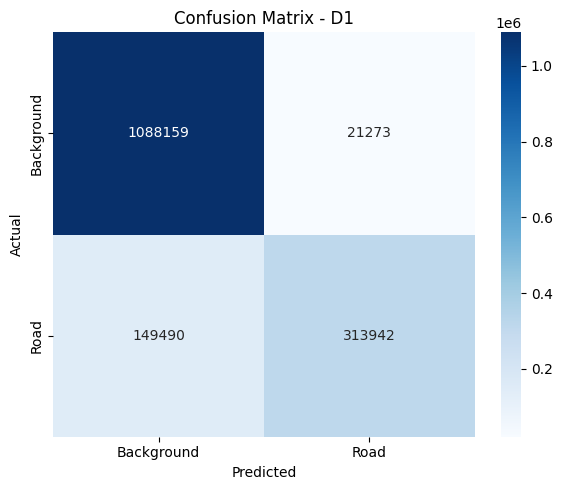


TESTING: D2
DILATION RATES: (4, 8, 12)
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step
Precision : 0.9059
Recall    : 0.0736
F1-score  : 0.1361
Dice      : 0.1361
Accuracy  : 0.7248
IoU       : 0.0730


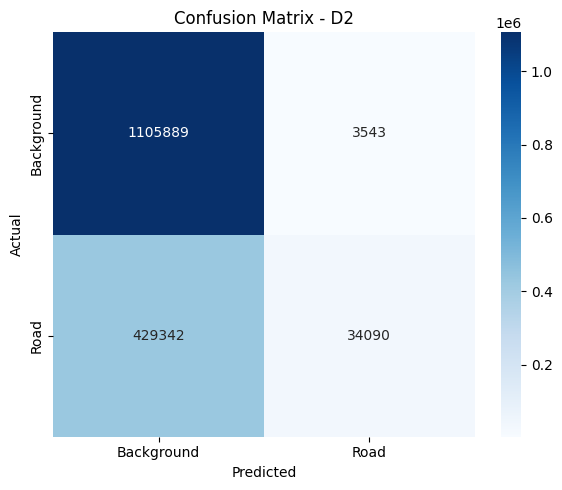


TESTING: D4
DILATION RATES: (8, 16, 24)
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step
Precision : 0.7995
Recall    : 0.4136
F1-score  : 0.5452
Dice      : 0.5452
Accuracy  : 0.7967
IoU       : 0.3748


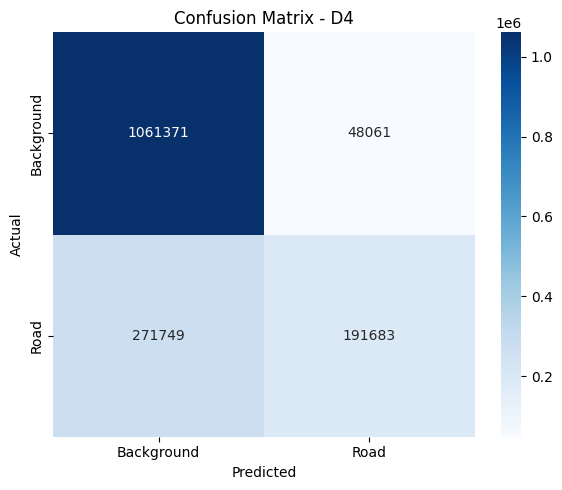


FINAL RESULTS
Experiment Dilation Rates  Precision   Recall  F1-Score     Dice  Accuracy      IoU
        D1      (3, 6, 9)   0.936539 0.677428  0.786185 0.786185  0.891432 0.647697
        D2     (4, 8, 12)   0.905854 0.073560  0.136070 0.136070  0.724779 0.073002
        D4    (8, 16, 24)   0.799532 0.413616  0.545192 0.545192  0.796670 0.374752


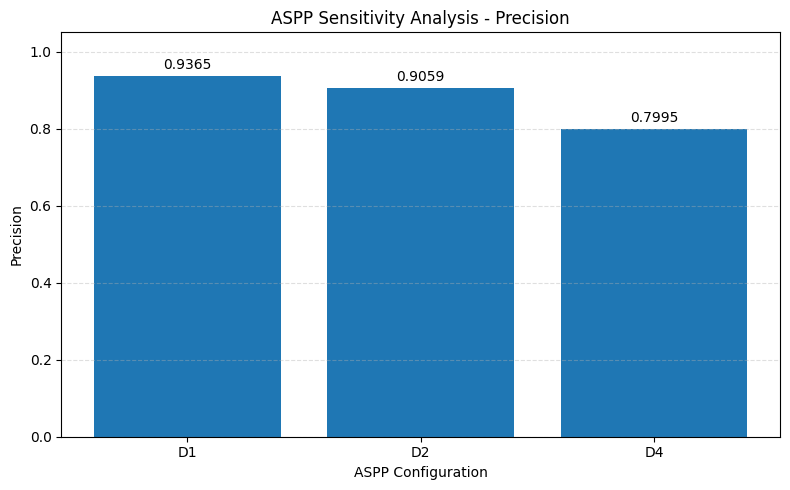

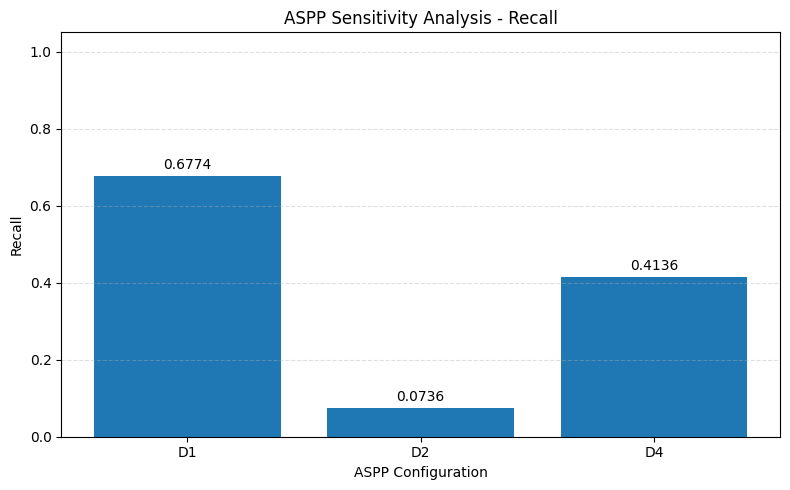

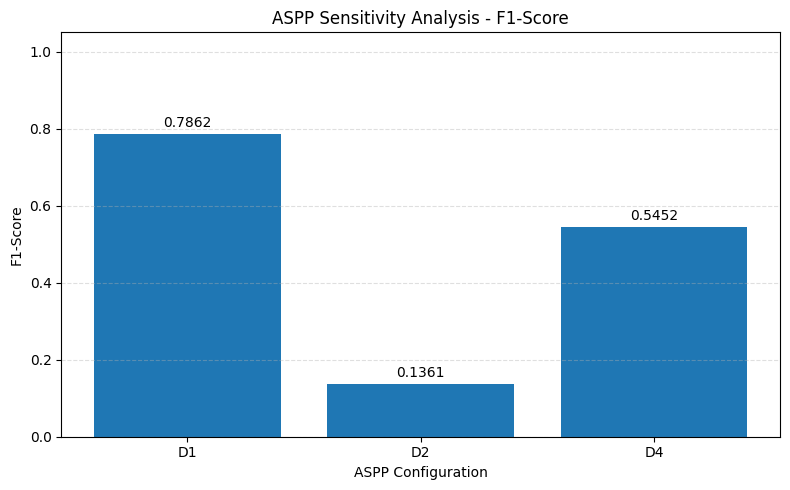

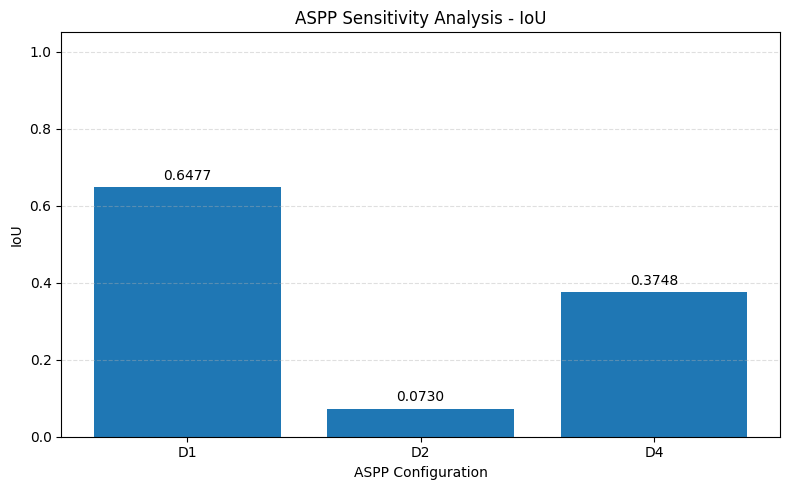

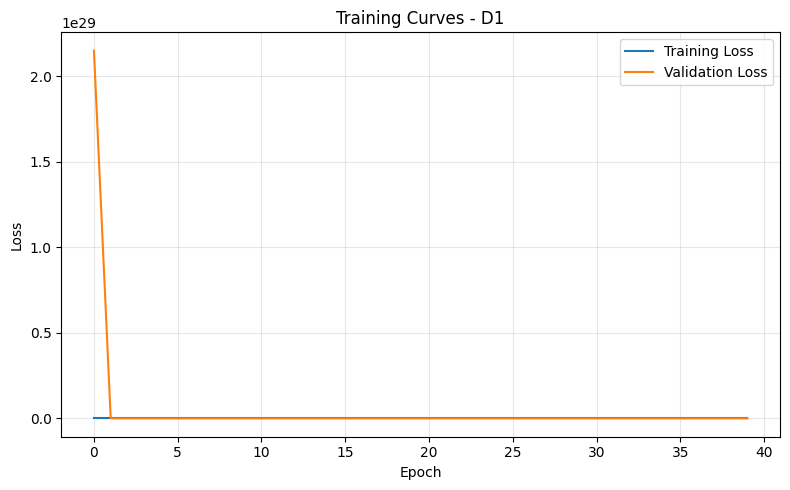

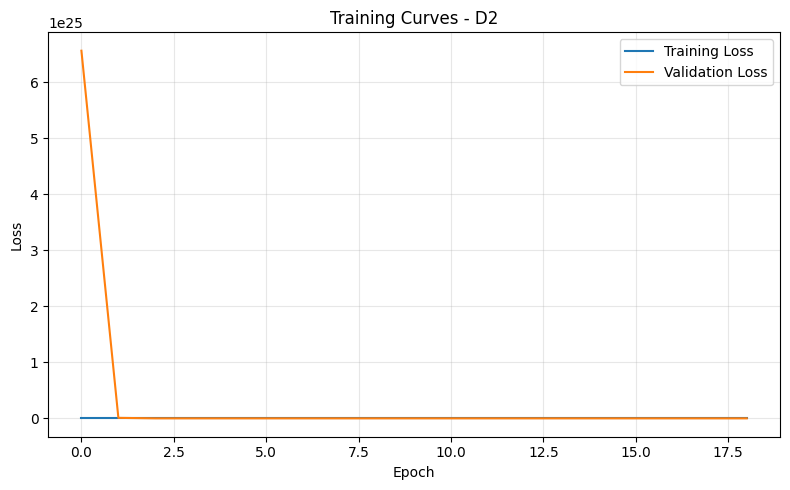

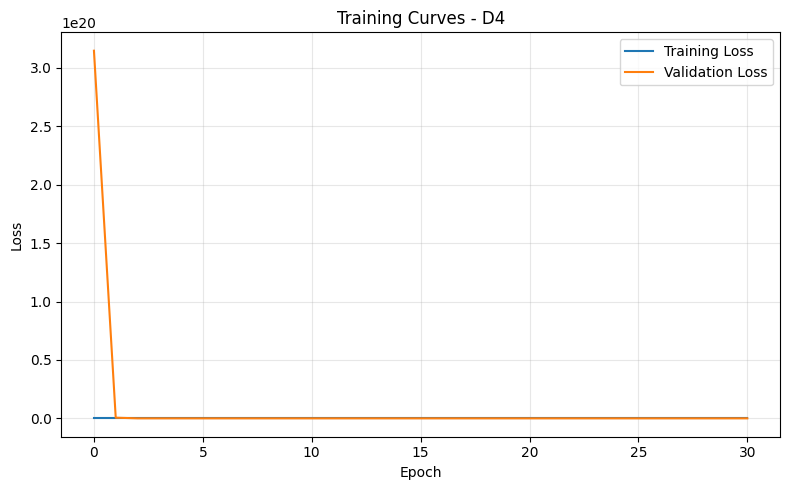


ASPP SENSITIVITY ANALYSIS COMPLETED
Results directory: ASPP_Sensitivity_Results


In [ ]:

# ================================================================
# ASPP DILATION RATE SENSITIVITY ANALYSIS
# Existing notebook model: attentionunet
#
# D1 = (3, 6, 9)
# D2 = (4, 8, 12)
# D4 = (8, 16, 24)
#
# Original configuration (6, 12, 18) is NOT retrained.
# ================================================================

import os
import gc
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras import layers, Model
from tensorflow.keras.layers import *
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix
)

# Fix np.random.seed if it was overwritten as an integer earlier in the notebook
if isinstance(np.random.seed, int):
    import importlib
    importlib.reload(np.random)

# ================================================================
# 1. CHECK EXISTING NOTEBOOK VARIABLES
# ================================================================

required_variables = [
    "X_train",
    "y_train",
    "X_test",
    "y_test_ground_truth",
    "input_shape"
]

for variable in required_variables:
    assert variable in globals(), f"{variable} is missing"

print("Existing data detected successfully.")

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test_ground_truth:", y_test_ground_truth.shape)

# ================================================================
# 2. CONFIGURABLE ASPP BLOCK
# ================================================================

def aspp_block(x, num_filters, rates=(6, 12, 18)):

    r1, r2, r3 = rates

    x1 = Conv2D(
        num_filters, (3, 3),
        dilation_rate=(r1, r1),
        padding="SAME"
    )(x)

    x1 = BatchNormalization()(x1)

    x2 = Conv2D(
        num_filters, (3, 3),
        dilation_rate=(r2, r2),
        padding="SAME"
    )(x)

    x2 = BatchNormalization()(x2)

    x3 = Conv2D(
        num_filters, (3, 3),
        dilation_rate=(r3, r3),
        padding="SAME"
    )(x)

    x3 = BatchNormalization()(x3)

    x4 = Conv2D(
        num_filters, (3, 3),
        dilation_rate=(1, 1),
        padding="SAME"
    )(x)

    x4 = BatchNormalization()(x4)

    y = Add()([x1, x2, x3, x4])

    y = Conv2D(
        num_filters, (1, 1),
        padding="SAME"
    )(y)

    return y


# ================================================================
# 3. CONFIGURABLE ATTENTIONUNET
# Uses your EXISTING encoder, decoder and attention functions.
# ================================================================

def attentionunet(input_shape, rates=(6, 12, 18)):

    n_filters = [16, 32, 64, 128, 256]

    inputs = layers.Input(input_shape)

    c0 = inputs

    c1 = stem_block(
        c0, n_filters[0], strides=1
    )

    # Encoder
    c2 = resnet_block(
        c1, n_filters[1], strides=2
    )

    c3 = resnet_block(
        c2, n_filters[2], strides=2
    )

    c4 = resnet_block(
        c3, n_filters[3], strides=2
    )

    c5 = resnet_block(
        c4, n_filters[4], strides=2
    )

    # ASPP bridge
    b1 = aspp_block(
        c5,
        n_filters[4],
        rates=rates
    )

    # Decoder
    d0 = attetion_block(c4, b1)
    d0 = UpSampling2D((2, 2))(d0)
    d0 = Concatenate()([d0, c4])
    d0 = resnet_block(d0, n_filters[4])

    d1 = attetion_block(c3, d0)
    d1 = UpSampling2D((2, 2))(d1)
    d1 = Concatenate()([d1, c3])
    d1 = resnet_block(d1, n_filters[3])

    d2 = attetion_block(c2, d1)
    d2 = UpSampling2D((2, 2))(d2)
    d2 = Concatenate()([d2, c2])
    d2 = resnet_block(d2, n_filters[2])

    d3 = attetion_block(c1, d2)
    d3 = UpSampling2D((2, 2))(d3)
    d3 = Concatenate()([d3, c1])
    d3 = resnet_block(d3, n_filters[1])

    # Output
    outputs = Conv2D(
        1, (1, 1),
        padding="same"
    )(d3)

    outputs = Activation(
        "sigmoid"
    )(outputs)

    return Model(inputs, outputs)


# ================================================================
# 4. EXPERIMENTAL CONFIGURATIONS
# ================================================================

dilation_configs = {
    "D1": (3, 6, 9),
    "D2": (4, 8, 12),
    "D4": (8, 16, 24)
}

# ================================================================
# 5. TRAINING PARAMETERS
# ================================================================

SEED = 42

EPOCHS = 100
BATCH_SIZE = 16
LEARNING_RATE = 0.001

OUTPUT_DIR = "ASPP_Sensitivity_Results"

os.makedirs(OUTPUT_DIR, exist_ok=True)

training_histories = {}

# ================================================================
# 6. TRAIN THREE EXPERIMENTS
# ================================================================

for exp_name, rates in dilation_configs.items():

    print("\n" + "=" * 65)
    print("EXPERIMENT:", exp_name)
    print("DILATION RATES:", rates)
    print("=" * 65)

    tf.keras.backend.clear_session()
    gc.collect()

    tf.keras.utils.set_random_seed(SEED)

    # Create model using existing architecture
    model = attentionunet(
        input_shape=input_shape,
        rates=rates
    )

    model.compile(
        optimizer=Adam(learning_rate=LEARNING_RATE),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    print("Total parameters:", model.count_params())

    checkpoint = tf.keras.callbacks.ModelCheckpoint(
        filepath=f"{OUTPUT_DIR}/{exp_name}_best.keras",
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    )

    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        min_delta=0.0001,
        mode="min",
        restore_best_weights=True,
        verbose=1
    )

    tensorboard = tf.keras.callbacks.TensorBoard(
        log_dir=f"{OUTPUT_DIR}/logs_{exp_name}"
    )

    history = model.fit(
        X_train,
        y_train,
        validation_split=0.2,
        batch_size=BATCH_SIZE,
        epochs=EPOCHS,
        callbacks=[
            checkpoint,
            early_stopping,
            tensorboard
        ],
        shuffle=True,
        verbose=1
    )

    training_histories[exp_name] = history.history

    np.save(
        f"{OUTPUT_DIR}/{exp_name}_history.npy",
        history.history
    )

    print(f"{exp_name} training completed.")

    del model
    tf.keras.backend.clear_session()
    gc.collect()


# ================================================================
# 7. TESTING AND METRIC CALCULATION
# ================================================================

evaluation_results = []

for exp_name, rates in dilation_configs.items():

    print("\n" + "=" * 65)
    print("TESTING:", exp_name)
    print("DILATION RATES:", rates)
    print("=" * 65)

    model = tf.keras.models.load_model(
        f"{OUTPUT_DIR}/{exp_name}_best.keras"
    )

    predictions = model.predict(
        X_test,
        batch_size=BATCH_SIZE,
        verbose=1
    )

    predictions_binary = (
        predictions > 0.5
    ).astype(np.uint8)

    y_true = np.asarray(
        y_test_ground_truth
    ).astype(np.uint8).flatten()

    y_pred = predictions_binary.flatten()

    assert len(y_true) == len(y_pred), \
        "Ground truth and prediction sizes differ."

    precision = precision_score(
        y_true, y_pred, zero_division=0
    )

    recall = recall_score(
        y_true, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_true, y_pred, zero_division=0
    )

    accuracy = accuracy_score(
        y_true, y_pred
    )

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    iou = (
        tp / (tp + fp + fn)
        if tp + fp + fn > 0 else 0
    )

    dice = (
        2 * tp / (2 * tp + fp + fn)
        if 2 * tp + fp + fn > 0 else 0
    )

    evaluation_results.append({
        "Experiment": exp_name,
        "Dilation Rates": str(rates),
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "Dice": dice,
        "Accuracy": accuracy,
        "IoU": iou
    })

    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1-score  : {f1:.4f}")
    print(f"Dice      : {dice:.4f}")
    print(f"Accuracy  : {accuracy:.4f}")
    print(f"IoU       : {iou:.4f}")

    # Confusion matrix
    cm = np.array([
        [tn, fp],
        [fn, tp]
    ])

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Background", "Road"],
        yticklabels=["Background", "Road"]
    )

    plt.title(f"Confusion Matrix - {exp_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/{exp_name}_Confusion_Matrix.png",
        dpi=300
    )

    plt.show()
    plt.close()

    del model
    tf.keras.backend.clear_session()
    gc.collect()


# ================================================================
# 8. SAVE RESULTS
# ================================================================

results_df = pd.DataFrame(evaluation_results)

results_df.to_csv(
    f"{OUTPUT_DIR}/ASPP_Sensitivity_Results.csv",
    index=False
)

print("\nFINAL RESULTS")
print(results_df.to_string(index=False))


# ================================================================
# 9. COMPARATIVE METRIC PLOTS
# ================================================================

for metric in ["Precision", "Recall", "F1-Score", "IoU"]:

    plt.figure(figsize=(8, 5))

    bars = plt.bar(
        results_df["Experiment"],
        results_df[metric]
    )

    plt.bar_label(
        bars,
        fmt="%.4f",
        padding=3
    )

    plt.xlabel("ASPP Configuration")
    plt.ylabel(metric)
    plt.title(f"ASPP Sensitivity Analysis - {metric}")

    plt.ylim(0, 1.05)
    plt.grid(axis="y", linestyle="--", alpha=0.4)

    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/{metric}_Comparison.png",
        dpi=300
    )

    plt.show()
    plt.close()


# ================================================================
# 10. TRAINING LOSS CURVES
# ================================================================

for exp_name, history in training_histories.items():

    plt.figure(figsize=(8, 5))

    plt.plot(
        history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history["val_loss"],
        label="Validation Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"Training Curves - {exp_name}")

    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/{exp_name}_Loss_Curve.png",
        dpi=300
    )

    plt.show()
    plt.close()


print("\n" + "=" * 65)
print("ASPP SENSITIVITY ANALYSIS COMPLETED")
print("Results directory:", OUTPUT_DIR)
print("=" * 65)
